# 7. Can the zone be recognised from a single strike?

A random forest (100 trees, 15 spectral features per strike) predicts the **zone** (24 classes) of each strike. Strikes
of the same recording are alike (same phone, same position, same moment): if they fall on both sides of a random
split, the model "recognises the recording", not the zone. The main evaluation is therefore **leave-one-recording-out**
cross-validation within the characterisation set (notebook 01, section 1.3): each recording is predicted by a model
trained on the others, which contain strikes of the same zones recorded at another moment. The result of a random
70/30 split of the strikes is also given as a reference. Finally, the model trained on the whole characterisation set
is tested on the **validation recordings**, which were not used in any analysis (section 7.3).

**Inputs:** `intermediate/features.csv` (01), `data/geometry/zone_coordinates.csv`.
**Outputs:** `tables/t07_validation.csv`, `tables/t07_per_recording.csv`, `figures/fig07a_validation.png`,
`figures/fig07b_zone_confusion.png`.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # folder with config.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config as C
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.4})
pd.set_option("display.precision", 2)

import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict, train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
F = C.RF_FEATURES
rf = lambda: RandomForestClassifier(random_state=C.SEED)
N_PERM = 100

## 7.1 Strikes and recordings

In [2]:
allf = pd.read_csv(C.INTERMEDIATE / "features.csv")
d = allf[allf.set == "characterisation"].reset_index(drop=True)     # characterisation set
val = allf[allf.set == "validation"].reset_index(drop=True)         # validation recordings
print(f"Characterisation: {len(d)} strikes, {d.file.nunique()} recordings, {d.zone.nunique()} zones; "
      f"recordings per zone: {d.groupby('zone').file.nunique().min()}–{d.groupby('zone').file.nunique().max()}; "
      f"strikes per zone: {d.groupby('zone').size().min()}–{d.groupby('zone').size().max()}")
print(f"Validation: {len(val)} strikes, {val.file.nunique()} recordings, {val.zone.nunique()} zones")

Characterisation: 371 strikes, 11 recordings, 24 zones; recordings per zone: 2–4; strikes per zone: 10–20
Validation: 242 strikes, 7 recordings, 24 zones


## 7.2 Two ways of evaluating the same model

Random forest with 100 trees (`random_state = 42`) and the 15 features.

- **Random 70/30**: strikes of the same recording on both sides (optimistic reference).
- **Leave one recording out**: each recording of the characterisation set is predicted by a model trained on the
  others.

The chance level is estimated with 100 permutations: the zone is shuffled between **runs** (the consecutive strikes of
a zone in a recording keep a common label, but it belongs to another run) and the leave-one-recording-out validation is
repeated. The model can thus still recognise the run, but it cannot be right in another recording except by chance.
(Shuffling the labels between zones does not work: it is only a renaming.) The uncertainty is estimated with a
bootstrap over recordings (2000 replicates).

In [3]:
rng = np.random.default_rng(C.SEED)
cv = LeaveOneGroupOut()
X, g, y = d[F], d.file, d.zone
zones = np.sort(d.zone.unique())
Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, random_state=C.SEED, stratify=y)
acc_rand = accuracy_score(yb, rf().fit(Xa, ya).predict(Xb))
yp = cross_val_predict(rf(), X, y, groups=g, cv=cv, n_jobs=-1)
ok = (yp == y.values); acc = ok.mean()
recs = g.unique()
boot = [ok[np.concatenate([np.where(g.values == a)[0] for a in rng.choice(recs, len(recs))])].mean() for _ in range(2000)]
null = []
runs = d.groupby(["zone", "file"]).ngroup().values; run_zone = d.groupby(["zone", "file"]).zone.first().values
for _ in range(N_PERM):
    yperm = pd.Series(rng.permutation(run_zone)[runs])            # each run receives the zone of another run
    null.append(accuracy_score(yperm, cross_val_predict(rf(), X, yperm, groups=g, cv=cv, n_jobs=-1)))
null = np.array(null)
res = pd.DataFrame([{"target": "zone (24)", "random_70_30": acc_rand, "leave_one_recording_out": acc,
                     "leave_one_recording_out_CI95": f"{np.percentile(boot, 2.5):.2f}-{np.percentile(boot, 97.5):.2f}",
                     "leave_one_recording_out_balanced": balanced_accuracy_score(y, yp),
                     "majority_baseline": (y == y.mode()[0]).mean(),
                     "chance_median": np.median(null), "chance_p95": np.percentile(null, 95),
                     "p_permutation": (1 + (null >= acc).sum()) / (1 + len(null)), "n": len(d)}])
pr = (d.assign(ok=ok).groupby("file")
        .agg(zones=("zone", lambda z: ",".join(map(str, sorted(z.unique())))), strikes=("ok", "size"), accuracy=("ok", "mean"))
        .reset_index().rename(columns={"file": "recording"}).assign(set="characterisation (left out)"))
res.set_index("target").T

target,zone (24)
random_70_30,0.84
leave_one_recording_out,0.64
leave_one_recording_out_CI95,0.58-0.68
leave_one_recording_out_balanced,0.64
majority_baseline,0.05
chance_median,0.03
chance_p95,0.06
p_permutation,0.01
n,371


## 7.3 Validation with recordings not used in the analysis

The model is trained on all strikes of the characterisation set and predicts the zone (among the 24) of each strike of
the validation recordings, which cover the 24 zones. The confidence interval is obtained with a bootstrap over the
validation recordings (2000 replicates). The chance level is estimated with 100 models trained with the zone shuffled
between the runs of the characterisation set.

In [4]:
model = rf().fit(d[F], d.zone)
yv = model.predict(val[F]); okv = yv == val.zone.values
gv = val.file.values; recv = np.unique(gv)
bootv = [okv[np.concatenate([np.where(gv == a)[0] for a in rng.choice(recv, len(recv))])].mean() for _ in range(2000)]
nullv = np.array([accuracy_score(val.zone, rf().fit(d[F], rng.permutation(run_zone)[runs]).predict(val[F]))
                  for _ in range(N_PERM)])
res["validation_recordings"] = len(recv); res["validation_strikes"] = len(val); res["validation_zones"] = val.zone.nunique()
res["validation_accuracy"] = okv.mean()
res["validation_CI95"] = f"{np.percentile(bootv, 2.5):.2f}-{np.percentile(bootv, 97.5):.2f}"
res["validation_balanced"] = balanced_accuracy_score(val.zone, yv)
res["validation_chance_median"] = np.median(nullv); res["validation_chance_p95"] = np.percentile(nullv, 95)
res["validation_p"] = (1 + (nullv >= okv.mean()).sum()) / (1 + len(nullv))
res.to_csv(C.TABLES / "t07_validation.csv", index=False)
pv = (val.assign(ok=okv).groupby("file")
         .agg(zones=("zone", lambda z: ",".join(map(str, sorted(z.unique())))), strikes=("ok", "size"), accuracy=("ok", "mean"))
         .reset_index().rename(columns={"file": "recording"}).assign(set="validation"))
pr = pd.concat([pr, pv], ignore_index=True); pr.to_csv(C.TABLES / "t07_per_recording.csv", index=False)
xy = pd.read_csv(C.COORDINATES).set_index("zone"); ev = val.assign(pred=yv)[~okv]
dv = np.hypot(xy.loc[ev.zone, "x_m"].values - xy.loc[ev.pred, "x_m"].values, xy.loc[ev.zone, "y_m"].values - xy.loc[ev.pred, "y_m"].values)
print(f"Validation: {okv.mean():.0%} of {len(val)} strikes (95 % CI {res.validation_CI95.iloc[0]}; balanced "
      f"{res.validation_balanced.iloc[0]:.0%}); chance: median {np.median(nullv):.0%}, 95th percentile {np.percentile(nullv, 95):.0%}; "
      f"p = {res.validation_p.iloc[0]:.3f}")
print(f"Errors: median distance between true and predicted zone {np.median(dv):.2f} m")

Validation: 73% of 242 strikes (95 % CI 0.58-0.87; balanced 68%); chance: median 4%, 95th percentile 8%; p = 0.010
Errors: median distance between true and predicted zone 0.87 m


In [5]:
pr.round(2)

,recording,zones,strikes,accuracy,set
0,20251019-140152.wav,"1,2,3,4,5,6,7,8,9,10",50,0.74,characterisation (left out)
1,20251019-140412.wav,"1,2,3,4,5,6,7,8,9,10",50,0.66,characterisation (left out)
2,20251019-140629.wav,"1,2,3,4,5,6,7,8,9,10",51,0.71,characterisation (left out)
3,20251019-141757.wav,"11,12,13,14,15,16,17,18,19",39,0.51,characterisation (left out)
4,20251019-142014.wav,"11,12,13,14,15,16,17,18,19",44,0.61,characterisation (left out)
5,20251019-143811.wav,"20,21,22,23,24",25,0.52,characterisation (left out)
6,20251019-144311.wav,"20,21,22,23,24",25,0.72,characterisation (left out)
7,20251019-150207.wav,"15,16,17,18,19",24,0.54,characterisation (left out)
8,20251019-150644.wav,"15,16,17,18,19",25,0.56,characterisation (left out)
9,20251019-151007.wav,"11,12,13,14",19,0.63,characterisation (left out)


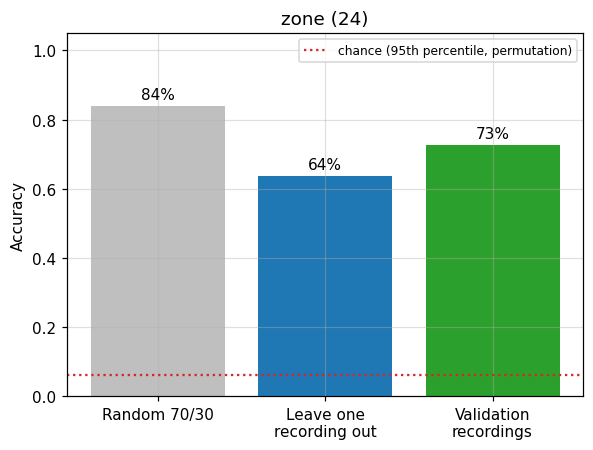

In [6]:
r = res.iloc[0]
fig, ax = plt.subplots(figsize=(5.5, 4.2))
v = [r.random_70_30, r.leave_one_recording_out, r.validation_accuracy]
ax.bar(["Random 70/30", "Leave one\nrecording out", "Validation\nrecordings"], v, color=["0.75", "C0", "C2"])
ax.axhline(r.chance_p95, color="C3", ls=":", lw=1.5, label="chance (95th percentile, permutation)")
for i, val_ in enumerate(v): ax.text(i, val_ + .02, f"{val_:.0%}", ha="center")
ax.set_ylim(0, 1.05); ax.set_title(r.target); ax.set_ylabel("Accuracy"); ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig(C.FIGURES / "fig07a_validation.png", dpi=150, bbox_inches="tight"); plt.show()

## 7.4 Which zones is a strike confused with? (characterisation set)

If the timbre changed smoothly over the stone (notebook 04), the zone errors would fall on **neighbouring** zones. The
distance between the true and the predicted zone is compared with the distance between random pairs of zones.

Zone errors: 135 of 371
Median distance between true and predicted zone in the errors: 0.73 m; between any two zones: 0.88 m (Mann–Whitney p = 0.16)


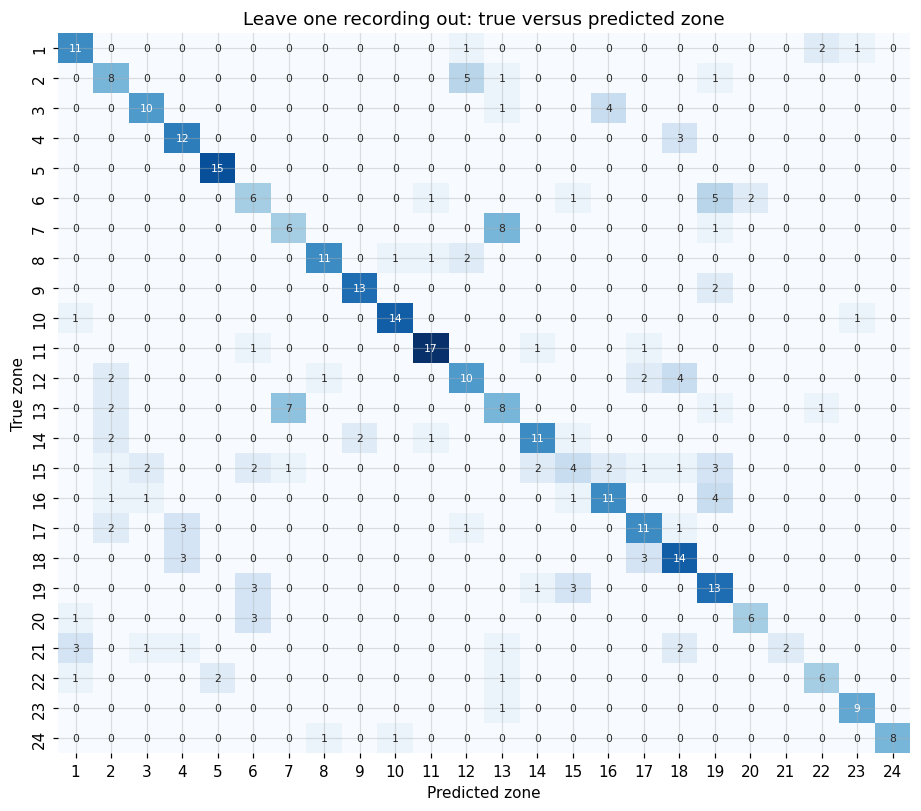

In [7]:
from scipy.stats import mannwhitneyu
pz = d.assign(pred=yp)
err = pz[pz.pred != pz.zone]
dist = np.hypot(xy.loc[err.zone, "x_m"].values - xy.loc[err.pred, "x_m"].values,
                xy.loc[err.zone, "y_m"].values - xy.loc[err.pred, "y_m"].values)
pairs = [np.hypot(*(xy.loc[i, ["x_m", "y_m"]].values - xy.loc[j, ["x_m", "y_m"]].values)) for i in xy.index for j in xy.index if i != j]
print(f"Zone errors: {len(err)} of {len(pz)}")
print(f"Median distance between true and predicted zone in the errors: {np.median(dist):.2f} m; "
      f"between any two zones: {np.median(pairs):.2f} m (Mann–Whitney p = {mannwhitneyu(dist, pairs, alternative='less').pvalue:.2g})")
cm = confusion_matrix(pz.zone, pz.pred, labels=zones)
plt.figure(figsize=(10, 8.5))
sns.heatmap(pd.DataFrame(cm, index=zones, columns=zones), cmap="Blues", annot=True, fmt="d", cbar=False, annot_kws={"size": 7})
plt.xlabel("Predicted zone"); plt.ylabel("True zone"); plt.title("Leave one recording out: true versus predicted zone")
plt.savefig(C.FIGURES / "fig07b_zone_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

## 7.5 Conclusion

See `t07_validation.csv`. The random split overestimates what the model does on new recordings, but the
leave-one-recording-out accuracy and the accuracy on the validation recordings remain far above chance: **a single
strike keeps an acoustic signature of its position** that is reproduced in other recordings of the same zone.